## Exercício de Retropropagação
Neste exercício utilizaremos retropropagação para treinar um perceptron multicamadas (com uma única camada oculta). Experimentaremos com diferentes padrões e veremos quão rapidamente ou lentamente os pesos convergem. Observaremos o impacto e a interação de diferentes parâmetros como taxa de aprendizagem, número de iterações e número de pontos de dados.

In [85]:
from __future__ import division, print_function
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Preencha o código abaixo para que ele crie um perceptron multicamadas com uma única camada oculta (com 4 nós) e o treine via retropropagação. Especificamente, seu código deve:

1. Inicializar os pesos com valores aleatórios entre -1 e 1 - FEITO
1. Realizar a computação de propagação direta (feed-forward) - FEITO
1. Calcular a função de perda - FEITO
1. Calcular os gradientes para todos os pesos via retropropagação - FEITO
1. Atualizar as matrizes de peso (usando um parâmetro learning_rate) - FEITO
1. Executar os passos 2-5 por um número fixo de iterações - FEITO
1. Plotar as acurácias e log loss e observar como elas mudam ao longo do tempo - FEITO


Uma vez que seu código esteja funcionando, teste-o para os diferentes padrões abaixo.

- Quais padrões a rede neural conseguiu aprender rapidamente e quais demoraram mais?
- Que taxas de aprendizagem e números de iterações funcionaram bem?
- Se você tiver tempo, tente variar o tamanho da camada oculta e experimente com diferentes funções de ativação (ex: ReLu)

shape do x_mat (500, 3)
shape do y (500, 1)




/tmp/ipykernel_3053358/1851989503.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  ax.plot(x_mat_full[y==1, 0],x_mat_full[y==1, 1], 'ro', label='class 1', color='darkslateblue')
/tmp/ipykernel_3053358/1851989503.py:34: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bx" (-> color='b'). The keyword argument will take precedence.
  ax.plot(x_mat_full[y==0, 0],x_mat_full[y==0, 1], 'bx', label='class 0', color='chocolate')


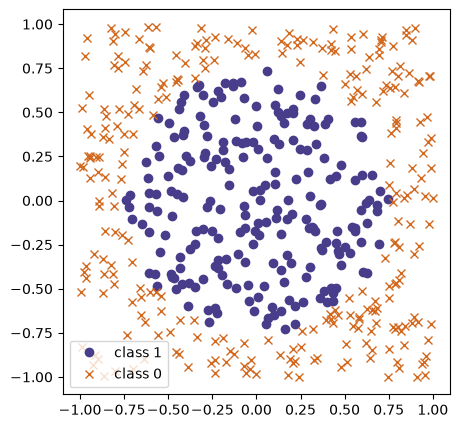

In [86]:
## O código abaixo gera dois valores x e um valor y de acordo com diferentes padrões
## Também cria um termo de "viés" (um vetor de 1s)
## O objetivo é então aprender o mapeamento de x para y usando uma rede neural via retropropagação

num_obs = 500 # número de entradas
x_mat_1 = np.random.uniform(-1,1,size = (num_obs,2)) # matriz (500, 2) com valores entre -1 e 1
x_mat_bias = np.ones((num_obs,1)) # vetor (500, 1) com varios 1
x_mat_full = np.concatenate( (x_mat_1,x_mat_bias), axis=1) # matriz (500, 3), junta as duas de cima

# ESCOLHA UM PADRÃO ABAIXO e comente o restante.

# # Padrão circular
y = (np.sqrt(x_mat_full[:,0]**2 + x_mat_full[:,1]**2)<.75).astype(int)

# # Padrão losango
#y = ((np.abs(x_mat_full[:,0]) + np.abs(x_mat_full[:,1]))<1).astype(int)

# # Quadrado centralizado
# y = ((np.maximum(np.abs(x_mat_full[:,0]), np.abs(x_mat_full[:,1])))<.5).astype(int)

# # Padrão ângulo reto espesso
#y = (((np.maximum((x_mat_full[:,0]), (x_mat_full[:,1])))<.5) & ((np.maximum((x_mat_full[:,0]), (x_mat_full[:,1])))>-.5)).astype(int)

# # Padrão ângulo reto fino
#y = (((np.maximum((x_mat_full[:,0]), (x_mat_full[:,1])))<.5) & ((np.maximum((x_mat_full[:,0]), (x_mat_full[:,1])))>0)).astype(int)
y_c = y.reshape(500, 1)

print('shape do x_mat {}'.format(x_mat_full.shape))
print('shape do y {}'.format(y_c.shape))
print("\n")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x_mat_full[y==1, 0],x_mat_full[y==1, 1], 'ro', label='class 1', color='darkslateblue')
ax.plot(x_mat_full[y==0, 0],x_mat_full[y==0, 1], 'bx', label='class 0', color='chocolate')
# ax.grid(True)
ax.legend(loc='best')
ax.axis('equal');

Aqui estão algumas funções auxiliares

In [87]:
def sigmoid(x):
    """
    Função sigmoide
    """
    return 1.0 / (1.0 + np.exp(-x))


def loss_fn(y_true, y_pred, eps=1e-16):
    """
    Função de perda que gostaríamos de otimizar (minimizar)
    Estamos usando Perda Logarítmica
    http://scikit-learn.org/stable/modules/model_evaluation.html#log-loss
    """
    y_pred = np.maximum(y_pred,eps)
    y_pred = np.minimum(y_pred,(1-eps))
    return -(np.sum(y_true * np.log(y_pred)) + np.sum((1-y_true)*np.log(1-y_pred)))/len(y_true)


def forward_pass(W1, W2):
    """
    Executa uma computação direta da rede neural
    Recebe a entrada `x_mat_full` (variável global) e produz a saída `y_pred`
    Também produz o gradiente da função de perda logarítmica
    """
    global x_mat_full # (500, 3)
    global y # (500, 1)
    global num_

    """
    o problema pede camada oculta com 4 nos
    x_mat_full = (500,3)
    w1 = (4, 3).T a ultima coluna é bias
    W2 = (1, 4).T pra ficar a saida (500, 1)
    """

    # Primeiro, calcule as novas previsões `y_pred`

    z_2 = np.dot(x_mat_full, W_1) # (500, 3) @ (3, 4) == (500, 4)
    a_2 = sigmoid(z_2) # (500, 4)
    z_3 = np.dot(a_2, W_2) # (500, 4) @ (4, 1) == (500, 1)
    y_pred = sigmoid(z_3)#.reshape((len(x_mat_full),))


    # Agora calcule o gradiente

    J_z_3_grad = -y_c + y_pred # (500, 1) a derivada em relacao a y^ corta com a em relação a z3, o log loss ' não é isso ai
    J_W_2_grad = np.dot(J_z_3_grad.T, a_2).T # (1, 500) @ (500, 4) == (1, 4).T -> (4, 1); (500, ) vira (1, 500) no np, so se for unidimensional
    a_2_z_2_grad = sigmoid(z_2)*(1-sigmoid(z_2)) # (500, 4)
    J_W_1_grad = (np.dot((J_z_3_grad).reshape(-1,1), W_2.reshape(-1,1).T)*a_2_z_2_grad).T.dot(x_mat_full).T
    gradient = (J_W_1_grad, J_W_2_grad)
    
    # retorno
    return y_pred, gradient



def plot_loss_accuracy(loss_vals, accuracies):
    fig = plt.figure(figsize=(16, 8))
    fig.suptitle('Log Loss and Accuracy over iterations')
    
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(loss_vals)
    ax.grid(True)
    ax.set(xlabel='iterations', title='Log Loss')
    
    ax = fig.add_subplot(1, 2, 2)
    ax.plot(accuracies)
    ax.grid(True)
    ax.set(xlabel='iterations', title='Accuracy');

Complete o pseudocódigo abaixo

Acurácia: 0.492
Loss: 0.6730506685259822
Acurácia: 0.726
Loss: 0.581714135235382
Acurácia: 0.916
Loss: 0.3677269959074924
Acurácia: 0.932
Loss: 0.25289089370739876
Acurácia: 0.934
Loss: 0.21901759204802013
Acurácia: 0.936
Loss: 0.19983781498212955
Acurácia: 0.942
Loss: 0.1859588339085658
Acurácia: 0.948
Loss: 0.1749486140985518
Acurácia: 0.958
Loss: 0.16583240061810592
Acurácia: 0.96
Loss: 0.15808321678303028
Acurácia: 0.964
Loss: 0.15136561258833128
Acurácia: 0.966
Loss: 0.1454523279522541
Acurácia: 0.97
Loss: 0.14019038587711202
Acurácia: 0.972
Loss: 0.1354807529372602
Acurácia: 0.974
Loss: 0.13125783001920824
Acurácia: 0.974
Loss: 0.1274687737977975
Acurácia: 0.97
Loss: 0.12406089478490694
Acurácia: 0.972
Loss: 0.1209804139823654
Acurácia: 0.968
Loss: 0.11817688460834086
Acurácia: 0.968
Loss: 0.11560684902997241
Acurácia: 0.972
Loss: 0.11323478751041086
Acurácia: 0.972
Loss: 0.11103227814755218
Acurácia: 0.972
Loss: 0.1089765874586937
Acurácia: 0.972
Loss: 0.10704934440189023
Acurác

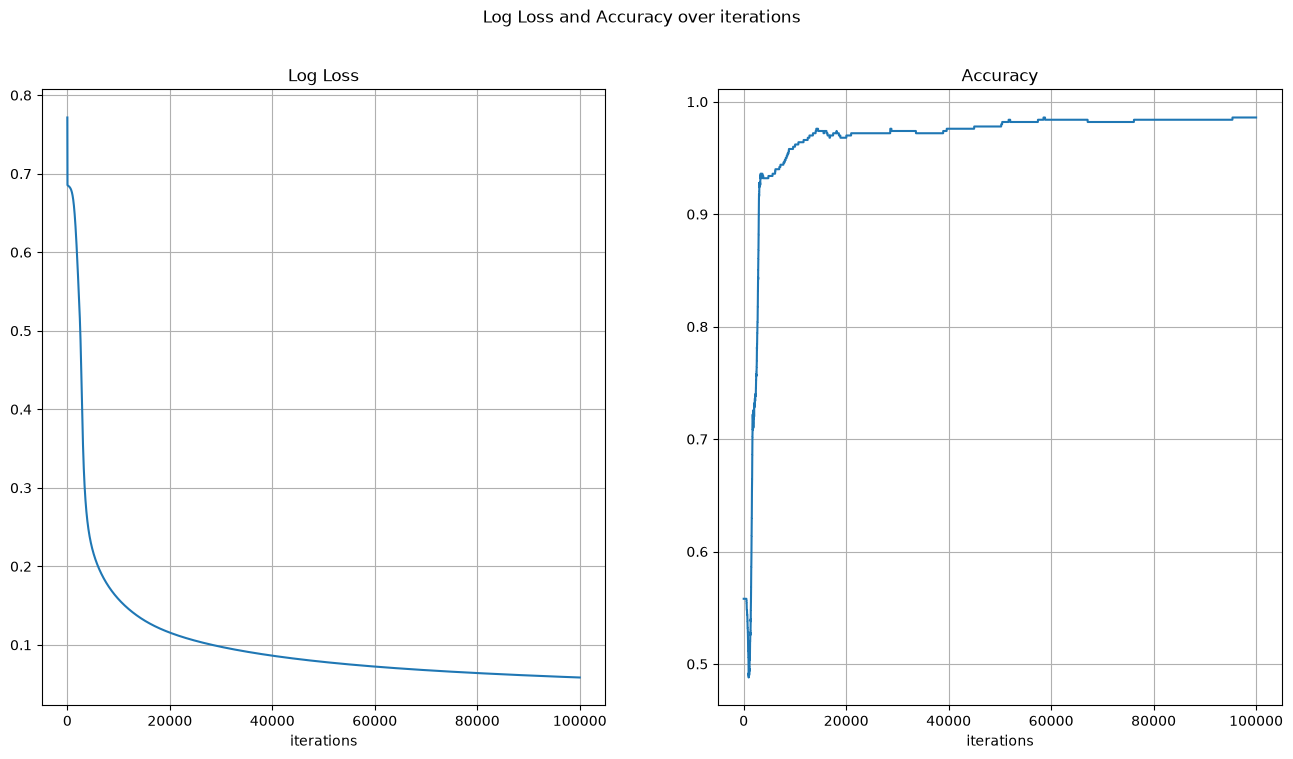

In [88]:
#### Inicialize os parâmetros da rede

np.random.seed(12345)

W_1 = np.random.uniform(-1, 1, size=(3, 4))
W_2 = np.random.uniform(-1, 1, size=(4, 1))
num_iter = 100000
learning_rate = .25
x_mat = x_mat_full

def normalizar(y):
    if y >= 0.5:
        return 1
    return 0

norm = np.vectorize(normalizar)

loss_vals, accuracies = [], []
cont = 0
n = x_mat_full.shape[0]
for i in range(num_iter):
    cont += 1
    ### Execute uma computação direta e obtenha o gradiente
    y_pred, (jw1_gradiente, jw2_gradiente) = forward_pass(W_1, W_2)
    ## Atualize as matrizes de peso
    W_1 = W_1 - (jw1_gradiente / n) * learning_rate 
    W_2 = W_2 - (jw2_gradiente / n) * learning_rate 
    ### Calcule a perda e a acurácia
    loss = loss_fn(y_c, y_pred)
    loss_vals.append(loss)
    acuracia = np.mean(y_c == norm(y_pred))
    accuracies.append(acuracia)
    ## Imprima a perda e a acurácia a cada 200ª iteração
    if cont == 1000: 
        cont = 0
        print(f'Acurácia: {acuracia}')
        print(f'Loss: {loss}')
    
plot_loss_accuracy(loss_vals, accuracies)

consegui corrigir os erros das operações matriciais e o codigo esta funcionando, mas o learning rate de 0.1 esta
mudando os gradientes de forma insignificante, a acuracia nao muda. Fui testando com learning rate de 0.1 ate 100,
o accuracy nao muda e o loss esta extremamente alto e sem mudar... como se a rede neural não aprendesse. 

Olhando algumas anotacoes das aulas, lembrei que nas operações matricias, n gradientes são somados, é necessario deixar
o gradiente médio. Vou testar as learning rates comuns, o aviso RuntimeWarning: overflow encountered in exp
return 1.0 / (1.0 + np.exp(-x)) pode estar indicando valores extremamente grandes.

O aviso sumiu mas o loss ainda aumenta... Eu percebi que o quanto maior a learning_rate, mais o losso cresce rápido

Ainda não havia plotado e decidir plotar, percebi que havia poucos erros, o que não condiz com o loss e a acurácia...
estou com 10000 loops e learning rate 1, não estava encontrando o problema, tive que recorrer a ia ( eu estou tentando aprender, espero que considere! ) e percebi que o problema era que eu usava y_c no código e y para calcular o loss e a
acurácia... agora o modelo está incrível! aprende bem e rápido! o loss cai rapidamente no começo e se regula no final de 
forma mais leve, assim como a acurácia

Tentei por um learning rate de 0.1 e desandou, a combinação 10000 loops e learning rate 1 funcionou incrivelmente bem,
tentei multiplicar os loops por 10 e dividir o learning rate, tambem funciona bem

melhor resultado: 
padrão angulo reto
num_iter = 100000
learning_rate = .25


#### Plotar as respostas previstas com erros em amarelo

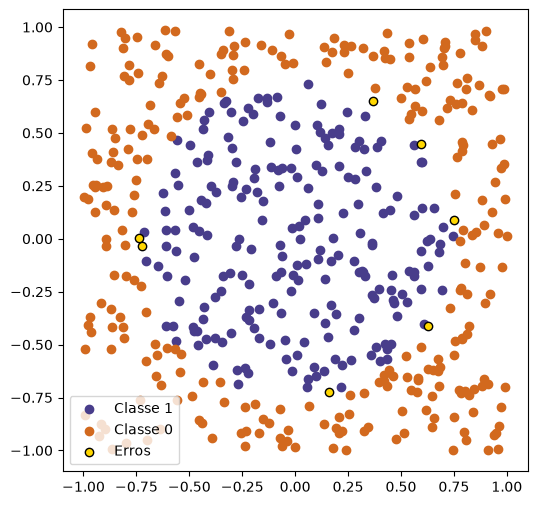

In [89]:

y_pred_norm = norm(y_pred).ravel()
y_true = y.ravel()

plt.figure(figsize=(6, 6))

plt.scatter(
    x_mat_full[(y_true == 1) & (y_pred_norm == 1), 0],
    x_mat_full[(y_true == 1) & (y_pred_norm == 1), 1],
    c="darkslateblue",
    label="Classe 1",
)
plt.scatter(
    x_mat_full[(y_true == 0) & (y_pred_norm == 0), 0],
    x_mat_full[(y_true == 0) & (y_pred_norm == 0), 1],
    c="chocolate",
    label="Classe 0",
)
plt.scatter(
    x_mat_full[y_true != y_pred_norm, 0],
    x_mat_full[y_true != y_pred_norm, 1],
    c="gold",
    edgecolors="black",
    label="Erros",
)

plt.legend()
plt.axis("equal")
plt.show()